# Taller 2 — Modelos de aprendizaje supervisado
**Aprendizaje Automático 1 — 2026-2** · Profesor: Daniel Rambaut · Modalidad: grupal

**Estudiantes:** Tania Fernanda Mora Cubillos · Over Haider Castrillón Valencia

Componente práctico-computacional (ejercicios 6 a 10) sobre dos conjuntos
reales incluidos en scikit-learn, por lo que el notebook se ejecuta de
principio a fin sin descargas externas:

- **Caso A** (`load_diabetes`, `scaled=False`): regresión de la progresión
  de la diabetes un año después de la medición inicial.
- **Caso B** (`load_breast_cancer`): clasificación de tejido, recodificado
  como **1 = maligno** y **0 = benigno**.

**Protocolo.** Partición fija 60/20/20 (entrenamiento, validación, prueba)
con `random_state=42`, estratificada en el caso B. Los modelos se ajustan
con entrenamiento, las decisiones se toman con validación y la prueba se
consulta una única vez, en el ejercicio 10, sobre modelos y umbrales ya
congelados.

In [1]:
import platform
import re
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import sklearn

from sklearn.datasets import load_diabetes, load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
)

%matplotlib inline

pd.set_option("display.float_format", lambda x: f"{x:,.4f}")
plt.rcParams["figure.dpi"] = 110
plt.rcParams["axes.grid"] = False

RANDOM_STATE = 42
COLORES = {"azul": "#4C72B0", "rojo": "#C44E52", "verde": "#55A868", "gris": "#8C8C8C"}

# Rutas relativas a notebook/ (build.py ejecuta con ese directorio de trabajo).
FIG_DIR = Path("../latex/figuras")
MACROS_PATH = Path("../latex/generado/resultados.tex")

pd.Series(
    {
        "Python": platform.python_version(),
        "numpy": np.__version__,
        "pandas": pd.__version__,
        "matplotlib": matplotlib.__version__,
        "scikit-learn": sklearn.__version__,
    },
    name="Versión",
).to_frame()

,Versión
Python,3.12.12
numpy,2.5.2
pandas,3.0.5
matplotlib,3.11.1
scikit-learn,1.9.0


### Funciones auxiliares

Se centralizan aquí las métricas y utilidades que usan varios ejercicios,
para que todas las tablas se calculen exactamente de la misma forma.

In [2]:
def rmse(y, y_pred):
    return mean_squared_error(y, y_pred) ** 0.5


def metricas_reg(y, y_pred):
    """MAE, RMSE y R² de un vector de predicciones continuas."""
    return {"MAE": mean_absolute_error(y, y_pred), "RMSE": rmse(y, y_pred), "R2": r2_score(y, y_pred)}


def predecir_umbral(proba, t):
    """Regla explícita ŷ = 1[p ≥ t] (evita los desempates internos de predict)."""
    return (np.asarray(proba) >= t).astype(int)


def metricas_clf(y, proba, t=0.5):
    """Precisión, recall, F1, ROC-AUC, FP, FN y costo L = FP + 5FN para un
    vector de probabilidades de la clase 1 (maligno) y un umbral t."""
    y_pred = predecir_umbral(proba, t)
    tn, fp, fn, tp = confusion_matrix(y, y_pred, labels=[0, 1]).ravel()
    return {
        "Umbral": t,
        "Precisión": precision_score(y, y_pred, zero_division=0),
        "Recall": recall_score(y, y_pred, zero_division=0),
        "F1": f1_score(y, y_pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y, proba),
        "TN": tn, "FP": fp, "FN": fn, "TP": tp,
        "Costo L": fp + 5 * fn,
    }


def seleccionar(tabla, orden):
    """Devuelve la fila ganadora de `tabla` aplicando criterios lexicográficos.

    `orden` es una lista de pares (columna, ascendente). Los valores reales se
    redondean a 10 decimales solo para comparar, de modo que diferencias de
    máquina no rompan un empate numérico; el ordenamiento es estable, así que
    ante un empate total gana la primera fila en el orden original de la
    cuadrícula.
    """
    claves = pd.DataFrame(index=tabla.index)
    for col, _ in orden:
        v = tabla[col]
        claves[col] = v.astype(float).round(10) if pd.api.types.is_float_dtype(v) else v
    ganador = claves.sort_values(
        [c for c, _ in orden], ascending=[a for _, a in orden], kind="mergesort"
    ).index[0]
    return tabla.loc[ganador]


def guardar_fig(fig, nombre):
    """Guarda la figura en latex/figuras/ para que el PDF use la misma imagen."""
    FIG_DIR.mkdir(parents=True, exist_ok=True)
    fig.savefig(FIG_DIR / f"{nombre}.png", dpi=200, bbox_inches="tight")


RESULTADOS = {}


def registrar(nombre, valor, decimales=4):
    """Registra una cifra para el LaTeX como macro \\<nombre>. Los nombres
    deben ser solo letras (restricción de los comandos de LaTeX)."""
    if not re.fullmatch(r"[A-Za-z]+", nombre):
        raise ValueError(f"Nombre de macro inválido para LaTeX: {nombre!r}")
    if isinstance(valor, (int, np.integer)):
        texto = str(int(valor))
    elif isinstance(valor, (float, np.floating)):
        texto = f"{valor:.{decimales}f}"
    else:
        texto = str(valor)
    RESULTADOS[nombre] = texto
    return valor


def escribir_macros():
    """Escribe latex/generado/resultados.tex con todas las cifras registradas."""
    MACROS_PATH.parent.mkdir(parents=True, exist_ok=True)
    lineas = [
        "% Archivo generado automáticamente por el notebook (no editar a mano).",
        *(f"\\newcommand{{\\{k}}}{{{v}}}" for k, v in sorted(RESULTADOS.items())),
    ]
    MACROS_PATH.write_text("\n".join(lineas) + "\n", encoding="utf-8")
    print(f"{len(RESULTADOS)} macros escritas en {MACROS_PATH}")

### Carga y partición de los datos

Código inicial del enunciado: primero se reserva el 20 % para prueba y
luego el 25 % del 80 % restante para validación, lo que deja
aproximadamente 60/20/20.

In [3]:
def separar(X, y, clasificacion=False):
    X_dev, X_test, y_dev, y_test = train_test_split(
        X, y, test_size=0.20, random_state=RANDOM_STATE,
        stratify=y if clasificacion else None,
    )
    X_train, X_val, y_train, y_val = train_test_split(
        X_dev, y_dev, test_size=0.25, random_state=RANDOM_STATE,
        stratify=y_dev if clasificacion else None,
    )
    return X_train, X_val, X_test, y_train, y_val, y_test


diabetes = load_diabetes(as_frame=True, scaled=False)
reg = separar(diabetes.data, diabetes.target)
Xr_train, Xr_val, Xr_test, yr_train, yr_val, yr_test = reg

cancer = load_breast_cancer(as_frame=True)
y_maligno = (cancer.target == 0).astype(int)
clf = separar(cancer.data, y_maligno, clasificacion=True)
Xc_train, Xc_val, Xc_test, yc_train, yc_val, yc_test = clf

tamanos = pd.DataFrame(
    {
        "Entrenamiento": [len(Xr_train), len(Xc_train)],
        "Validación": [len(Xr_val), len(Xc_val)],
        "Prueba": [len(Xr_test), len(Xc_test)],
    },
    index=["Caso A (diabetes)", "Caso B (cáncer de mama)"],
)
print("Tabla 0.1 — Tamaño de las particiones")
tamanos

Tabla 0.1 — Tamaño de las particiones


,Entrenamiento,Validación,Prueba
Caso A (diabetes),264,89,89
Caso B (cáncer de mama),341,114,114


## Ejercicio 6 — Caso A: regresión lineal simple y modelo de referencia

### a. Exploración en entrenamiento

Toda la exploración se hace sobre `Xr_train`/`yr_train`; validación y
prueba no se miran en esta etapa.

In [4]:
print("Tabla 6.1 — Tipos, faltantes y rangos (entrenamiento)")
pd.DataFrame(
    {
        "Tipo": Xr_train.dtypes.astype(str),
        "Faltantes": Xr_train.isnull().sum(),
        "Mínimo": Xr_train.min(),
        "Máximo": Xr_train.max(),
        "Media": Xr_train.mean(),
        "Desv. est.": Xr_train.std(),
    }
)

Tabla 6.1 — Tipos, faltantes y rangos (entrenamiento)


,Tipo,Faltantes,Mínimo,Máximo,Media,Desv. est.
age,float64,0,19.0000,79.0000,48.8409,12.7693
sex,float64,0,1.0000,2.0000,1.4886,0.5008
bmi,float64,0,18.9000,41.3000,26.4894,4.3824
bp,float64,0,62.0000,126.0000,94.3068,14.0341
s1,float64,0,110.0000,301.0000,187.4659,35.2901
s2,float64,0,41.6000,242.4000,114.6087,31.3018
s3,float64,0,22.0000,98.0000,48.8466,12.3035
s4,float64,0,2.0000,9.0900,4.0897,1.2737
s5,float64,0,3.5835,6.1070,4.6534,0.5024
s6,float64,0,58.0000,124.0000,92.3523,11.4221


In [5]:
print(f"Faltantes en la variable objetivo (entrenamiento): {yr_train.isnull().sum()}")
print("Tabla 6.2 — Resumen de la variable objetivo (entrenamiento)")
yr_train.describe().to_frame("target")

Faltantes en la variable objetivo (entrenamiento): 0
Tabla 6.2 — Resumen de la variable objetivo (entrenamiento)


,target
count,264.0000
mean,149.8106
std,78.9959
min,25.0000
25%,83.0000
50%,136.0000
75%,206.5000
max,346.0000


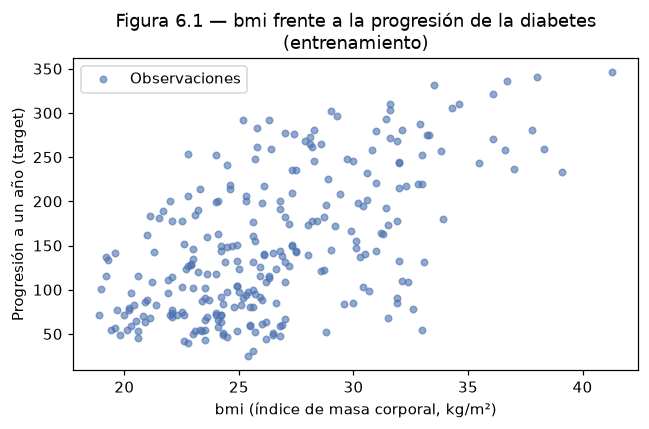

Correlación de Pearson bmi–target (entrenamiento): 0.5954


In [6]:
fig, ax = plt.subplots(figsize=(6, 4))
ax.scatter(Xr_train["bmi"], yr_train, s=18, alpha=0.6, color=COLORES["azul"], label="Observaciones")
ax.set_title("Figura 6.1 — bmi frente a la progresión de la diabetes\n(entrenamiento)")
ax.set_xlabel("bmi (índice de masa corporal, kg/m²)")
ax.set_ylabel("Progresión a un año (target)")
ax.legend()
plt.tight_layout()
guardar_fig(fig, "ex6_bmi_target")
plt.show()

print(f"Correlación de Pearson bmi–target (entrenamiento): "
      f"{registrar('CorrBmiTarget', Xr_train['bmi'].corr(yr_train)):.4f}")

TODO: análisis 6a

### b. Regresión simple con NumPy vs. `LinearRegression`

Se implementan las expresiones del ejercicio 1,
$\hat\beta_1 = \sum_i (x_i-\bar x)(y_i-\bar y) / \sum_i (x_i-\bar x)^2$ y
$\hat\beta_0 = \bar y - \hat\beta_1 \bar x$, usando solo `bmi`.

In [7]:
from sklearn.linear_model import LinearRegression
from sklearn.dummy import DummyRegressor

x_tr = Xr_train["bmi"].to_numpy()
y_tr = yr_train.to_numpy()
x_bar, y_bar = x_tr.mean(), y_tr.mean()
beta1_np = np.sum((x_tr - x_bar) * (y_tr - y_bar)) / np.sum((x_tr - x_bar) ** 2)
beta0_np = y_bar - beta1_np * x_bar

lr_simple = LinearRegression().fit(Xr_train[["bmi"]], yr_train)

pred_val_np = beta0_np + beta1_np * Xr_val["bmi"].to_numpy()
pred_val_sk = lr_simple.predict(Xr_val[["bmi"]])
dif_max = np.max(np.abs(pred_val_np - pred_val_sk))

print("Tabla 6.3 — Coeficientes de la regresión simple (entrenamiento)")
display(
    pd.DataFrame(
        {"NumPy": [beta0_np, beta1_np], "LinearRegression": [lr_simple.intercept_, lr_simple.coef_[0]]},
        index=["β0 (intercepto)", "β1 (pendiente bmi)"],
    )
)
print(f"Diferencia absoluta máxima entre predicciones de validación: {dif_max:.3e}")
print(f"np.allclose(NumPy, sklearn): {np.allclose(pred_val_np, pred_val_sk)}")
if dif_max == 0:
    registrar("SimpleDifMax", "0")
else:
    exp = int(np.floor(np.log10(dif_max)))
    registrar("SimpleDifMax", f"{dif_max / 10**exp:.1f}\\times 10^{{{exp}}}")

Tabla 6.3 — Coeficientes de la regresión simple (entrenamiento)


,NumPy,LinearRegression
β0 (intercepto),-134.5023,-134.5023
β1 (pendiente bmi),10.7331,10.7331


Diferencia absoluta máxima entre predicciones de validación: 5.684e-14
np.allclose(NumPy, sklearn): True


TODO: análisis 6b

### c. Comparación con `DummyRegressor`

In [8]:
dummy_reg = DummyRegressor(strategy="mean").fit(Xr_train, yr_train)

filas = []
for nombre, modelo, cols in [
    ("Constante (media)", dummy_reg, list(Xr_train.columns)),
    ("Regresión simple (bmi)", lr_simple, ["bmi"]),
]:
    for particion, X_, y_ in [("Entrenamiento", Xr_train, yr_train), ("Validación", Xr_val, yr_val)]:
        filas.append({"Modelo": nombre, "Partición": particion, **metricas_reg(y_, modelo.predict(X_[cols]))})
tabla_6c = pd.DataFrame(filas).set_index(["Modelo", "Partición"])
print("Tabla 6.4 — Constante vs. regresión simple (entrenamiento y validación)")
tabla_6c

Tabla 6.4 — Constante vs. regresión simple (entrenamiento y validación)


MAE    RMSE      R2
Modelo                 Partición                            
Constante (media)      Entrenamiento 66.6773 78.8462  0.0000
                       Validación    64.1288 75.6392 -0.0443
Regresión simple (bmi) Entrenamiento 51.5459 63.3458  0.3545
                       Validación    50.3475 58.5671  0.3739

In [9]:
for clave, nombre in [("Dummy", "Constante (media)"), ("Simple", "Regresión simple (bmi)")]:
    for sufijo, particion in [("Tr", "Entrenamiento"), ("Val", "Validación")]:
        for met in ["MAE", "RMSE", "R2"]:
            registrar(f"Reg{clave}{met.replace('2', 'dos')}{sufijo}", tabla_6c.loc[(nombre, particion), met])

TODO: análisis 6c

### d. Residuos de validación

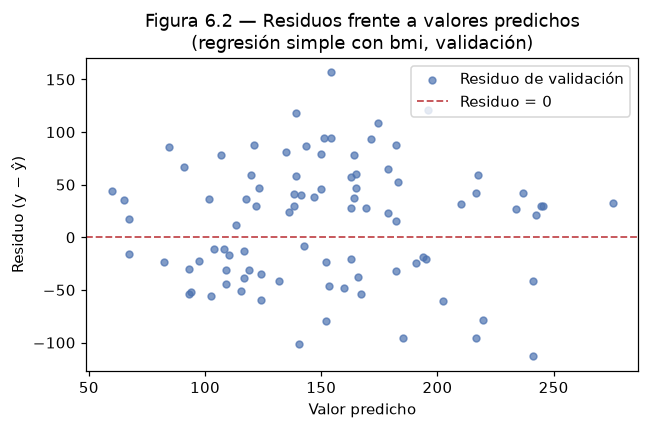

Desv. est. de residuos, mitad de predicciones bajas: 50.7598
Desv. est. de residuos, mitad de predicciones altas: 62.3648
Residuo mínimo: -113.1556 · residuo máximo: 156.7823


In [10]:
res_val = yr_val.to_numpy() - pred_val_sk
fig, ax = plt.subplots(figsize=(6, 4))
ax.scatter(pred_val_sk, res_val, s=20, alpha=0.7, color=COLORES["azul"], label="Residuo de validación")
ax.axhline(0, color=COLORES["rojo"], linestyle="--", linewidth=1.2, label="Residuo = 0")
ax.set_title("Figura 6.2 — Residuos frente a valores predichos\n(regresión simple con bmi, validación)")
ax.set_xlabel("Valor predicho")
ax.set_ylabel("Residuo (y − ŷ)")
ax.legend()
plt.tight_layout()
guardar_fig(fig, "ex6_residuos")
plt.show()

orden_pred = np.argsort(pred_val_sk)
mitad = len(orden_pred) // 2
print(f"Desv. est. de residuos, mitad de predicciones bajas: {res_val[orden_pred[:mitad]].std():.4f}")
print(f"Desv. est. de residuos, mitad de predicciones altas: {res_val[orden_pred[mitad:]].std():.4f}")
print(f"Residuo mínimo: {res_val.min():.4f} · residuo máximo: {res_val.max():.4f}")

TODO: análisis 6d

### e. Interpretación de coeficientes

In [11]:
print(f"Intercepto: {registrar('SimpleBetaCero', lr_simple.intercept_):.4f}")
print(f"Pendiente (bmi): {registrar('SimpleBetaUno', lr_simple.coef_[0]):.4f}")

Intercepto: -134.5023
Pendiente (bmi): 10.7331


TODO: análisis 6e

## Ejercicio 7 — Caso A: regresión múltiple y árbol de regresión

### a. Regresión múltiple con `Pipeline`

`StandardScaler` + `LinearRegression` con los diez predictores.

In [12]:
# TODO 7a

TODO: análisis 7a

### b. Coeficientes estandarizados y correlaciones

Coeficientes por magnitud absoluta; matriz de correlaciones de entrenamiento.

In [13]:
# TODO 7b

TODO: análisis 7b

### c. Cuadrícula de `DecisionTreeRegressor`

`max_depth` ∈ {2, 4, 6}, `min_samples_leaf` ∈ {5, 15, 30}; desempate: menor profundidad máxima, luego mayor mínimo por hoja.

In [14]:
# TODO 7c

TODO: análisis 7c

### d. Candidato final de regresión

Selección por RMSE de validación; desempate: simple, múltiple, árbol.

In [15]:
# TODO 7d

TODO: análisis 7d

### e. No linealidad y brecha entrenamiento–validación

In [16]:
# TODO 7e

TODO: análisis 7e

## Ejercicio 8 — Caso B: regresión logística y elección del umbral

### a. Particiones, recodificación y referencia

Proporción de malignos; `DummyClassifier(strategy="prior")`.

In [17]:
# TODO 8a

TODO: análisis 8a

### b. Selección de $C$

$C$ ∈ {0.01, 0.1, 1, 10}; mayor ROC-AUC de validación, en empate menor $C$; convergencia.

In [18]:
# TODO 8b

TODO: análisis 8b

### c. Umbral por costo $L = FP + 5FN$

$t$ ∈ {0.2, …, 0.8}; desempate: mayor recall, luego menor umbral.

In [19]:
# TODO 8c

TODO: análisis 8c

### d. Precisión y recall frente al umbral

In [20]:
# TODO 8d

TODO: análisis 8d

### e. Coeficientes estandarizados y odds

Signo de tres coeficientes; $e^{\beta_j}$ para uno de ellos.

In [21]:
# TODO 8e

TODO: análisis 8e

## Ejercicio 9 — Caso B: árbol de clasificación e interpretación

### a. Cuadrícula de `DecisionTreeClassifier`

`max_depth` ∈ {2, 3, 5, None}, `min_samples_leaf` ∈ {1, 5, 15}, sin estandarizar.

In [22]:
# TODO 9a

TODO: análisis 9a

### b. Selección del árbol

Mayor ROC-AUC de validación; desempate: menor profundidad real, menos hojas, orden de la cuadrícula.

In [23]:
# TODO 9b

TODO: análisis 9b

### c. Umbral del árbol y candidato final de clasificación

Mismos siete umbrales y desempates; comparación de costo con la logística.

In [24]:
# TODO 9c

TODO: análisis 9c

### d. Visualización y regla de una hoja

`plot_tree` truncado a tres niveles; ruta completa como `if`/`else`.

In [25]:
# TODO 9d

TODO: análisis 9d

### e. Importancias, coeficientes y sobreajuste

Cinco mayores `feature_importances_`.

In [26]:
# TODO 9e

TODO: análisis 9e

## Ejercicio 10 — Evaluación final y recomendación sustentada

### Candidatos congelados antes de abrir prueba

TODO

In [27]:
# TODO: tabla de candidatos (predictores, hiperparámetros, umbrales)

### a. Regresión en prueba

Constante, simple, múltiple y árbol; candidato elegido con validación.

In [28]:
# TODO 10a

TODO: análisis 10a

### b. Clasificación en prueba

Referencia ($t = 0.5$), logística y árbol con umbrales congelados.

In [29]:
# TODO 10b

TODO: análisis 10b

### c. Matrices de confusión y costo

Filas reales, columnas predichas, orden $[0, 1]$.

In [30]:
# TODO 10c

TODO: análisis 10c

### d. Recomendación

250 a 350 palabras.

In [31]:
# TODO 10d

TODO: análisis 10d

### Cifras para el documento LaTeX

In [32]:
escribir_macros()

16 macros escritas en ../latex/generado/resultados.tex
